# Simulação

## Objetivo da simulação

A simulação tem como objetivo calcular numericamente a DTFT de uma sequência discreta e analisar seu comportamento no domínio da frequência.

Será utilizada uma sequência com quatro amostras unitárias, permitindo comparar sua representação temporal com os espectros de magnitude e fase.

As atividades desenvolvidas serão:

1. Criar e representar a sequência discreta no domínio do tempo;
2. Calcular numericamente sua DTFT;
3. Determinar o espectro de magnitude;
4. Determinar o espectro de fase;
5. Identificar as frequências nas quais ocorrem os zeros espectrais;
6. Verificar a periodicidade da DTFT.

## Bibliotecas utilizadas

Para desenvolver a simulação, serão utilizadas as seguintes bibliotecas:

* **NumPy:** criação das sequências e realização dos cálculos numéricos;

* **Matplotlib:** construção e organização dos gráficos;

* **Seaborn:** configuração visual das representações gráficas.

## Código da simulação

A DTFT será calculada diretamente a partir de sua definição matemática, utilizando um conjunto de valores de frequência angular. Essa abordagem permite observar a transformação sem depender de uma implementação pronta da DFT ou da FFT.

In [1]:
# ============================================================
# IMPORTAÇÕES E CONFIGURAÇÕES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

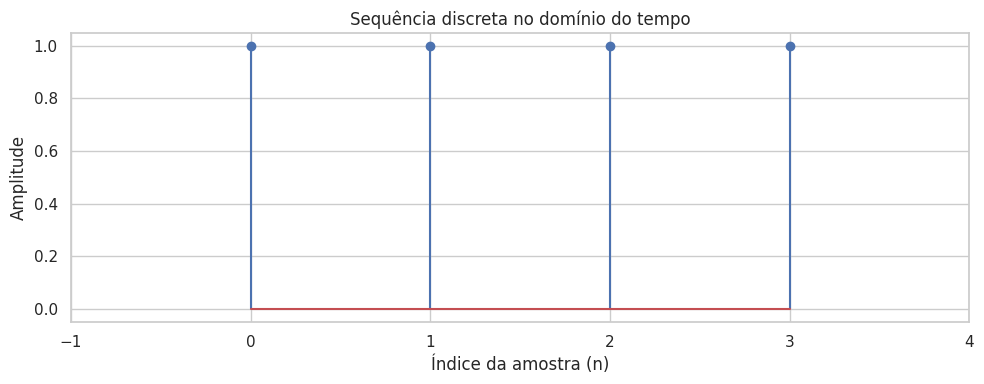

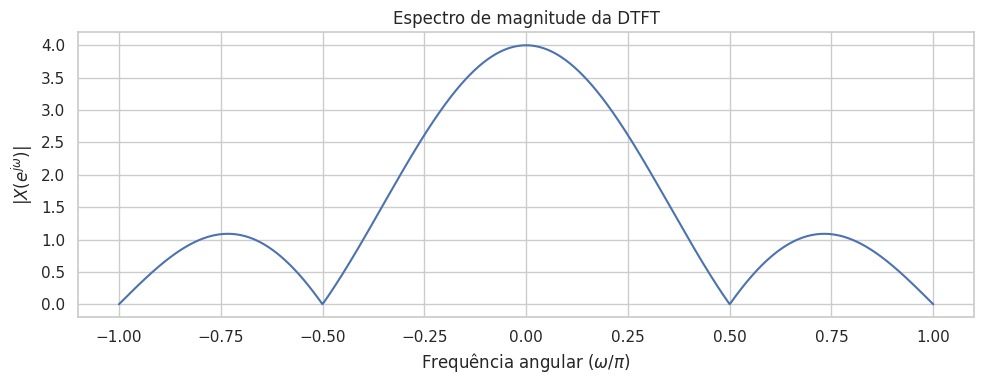

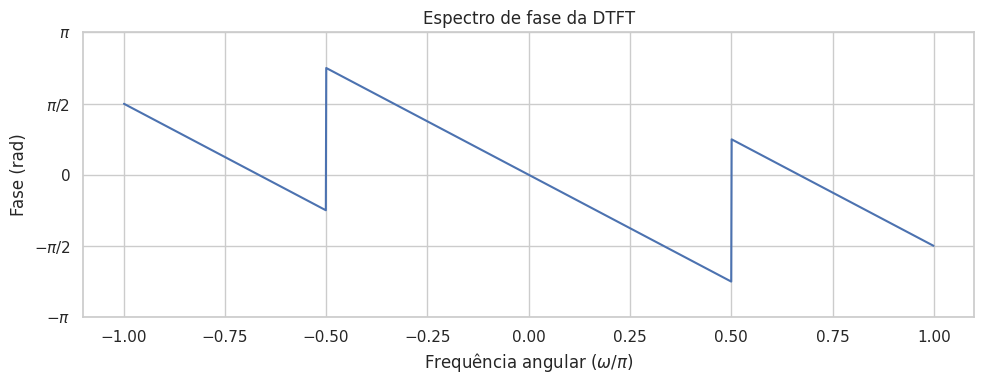

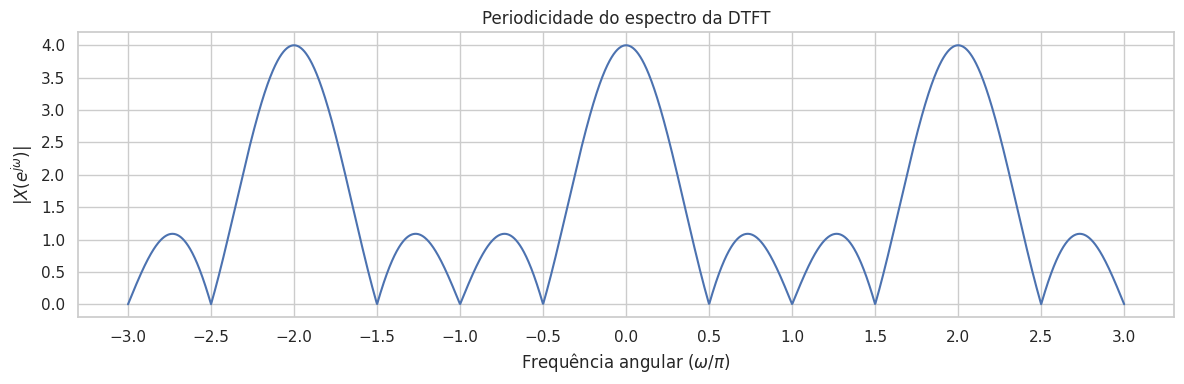

ANÁLISE DA DTFT
Sequência: [1 1 1 1]
Número de amostras: 4
Maior magnitude: 4.0000
Frequência do máximo: -0.0005 * pi rad/amostra
Valor da DTFT em omega = 0: 4.0000

Frequências dos zeros teóricos:
- pi/2, 0, pi/2 e seus múltiplos equivalentes,
exceto nos múltiplos de 2*pi.


In [2]:
# ============================================================
# DEFINIÇÃO DA SEQUÊNCIA DISCRETA
# ============================================================

n = np.arange(0, 4)

x = np.array([1, 1, 1, 1])

# ============================================================
# DEFINIÇÃO DO EIXO DE FREQUÊNCIA
# ============================================================

omega = np.linspace(
    -np.pi,
    np.pi,
    2000
)

# ============================================================
# CÁLCULO NUMÉRICO DA DTFT
# ============================================================

X = np.zeros(len(omega), dtype=complex)

for i, w in enumerate(omega):

    X[i] = np.sum(
        x * np.exp(-1j * w * n)
    )

# ============================================================
# CÁLCULO DA MAGNITUDE E DA FASE
# ============================================================

magnitude = np.abs(X)

fase = np.angle(X)

# Identificação dos pontos com magnitude próxima de zero
# Evita interpretar como significativa a fase de pontos nulos.

mascara = magnitude > 1e-8

fase_plot = np.where(
    mascara,
    fase,
    np.nan
)

# ============================================================
# 1. REPRESENTAÇÃO NO DOMÍNIO DO TEMPO
# ============================================================

plt.figure(figsize=(10, 4))

plt.stem(
    n,
    x
)

plt.title("Sequência discreta no domínio do tempo")
plt.xlabel("Índice da amostra (n)")
plt.ylabel("Amplitude")

plt.xticks(np.arange(-1, 5))
plt.grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 2. ESPECTRO DE MAGNITUDE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(
    omega / np.pi,
    magnitude
)

plt.title("Espectro de magnitude da DTFT")
plt.xlabel(r"Frequência angular ($\omega/\pi$)")
plt.ylabel(r"$|X(e^{j\omega})|$")

plt.xticks(
    np.arange(-1, 1.1, 0.25)
)

plt.grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 3. ESPECTRO DE FASE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(
    omega / np.pi,
    fase_plot
)

plt.title("Espectro de fase da DTFT")
plt.xlabel(r"Frequência angular ($\omega/\pi$)")
plt.ylabel("Fase (rad)")

plt.xticks(
    np.arange(-1, 1.1, 0.25)
)

plt.yticks(
    [-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
    [
        r"$-\pi$",
        r"$-\pi/2$",
        "0",
        r"$\pi/2$",
        r"$\pi$"
    ]
)

plt.grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 4. PERIODICIDADE DA DTFT
# ============================================================

omega_ext = np.linspace(
    -3 * np.pi,
    3 * np.pi,
    3000
)

X_ext = np.zeros(
    len(omega_ext),
    dtype=complex
)

for i, w in enumerate(omega_ext):

    X_ext[i] = np.sum(
        x * np.exp(-1j * w * n)
    )

plt.figure(figsize=(12, 4))

plt.plot(
    omega_ext / np.pi,
    np.abs(X_ext)
)

plt.title("Periodicidade do espectro da DTFT")
plt.xlabel(r"Frequência angular ($\omega/\pi$)")
plt.ylabel(r"$|X(e^{j\omega})|$")

plt.xticks(
    np.arange(-3, 3.1, 0.5)
)

plt.grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 5. VALORES IMPORTANTES DO ESPECTRO
# ============================================================

print("ANÁLISE DA DTFT")
print("=" * 45)

print(f"Sequência: {x}")
print(f"Número de amostras: {len(x)}")

indice_maximo = np.argmax(magnitude)

print(
    f"Maior magnitude: {magnitude[indice_maximo]:.4f}"
)

print(
    f"Frequência do máximo: "
    f"{omega[indice_maximo]/np.pi:.4f} * pi rad/amostra"
)

print(
    f"Valor da DTFT em omega = 0: "
    f"{np.sum(x):.4f}"
)

print("\nFrequências dos zeros teóricos:")
print("- pi/2, 0, pi/2 e seus múltiplos equivalentes,")
print("exceto nos múltiplos de 2*pi.")